# Predicting CPE with XGBoost

Goal: predict CPE + find its drivers. One change per experiment (leakage, tuning, outliers, ablation, classification). All scored on validation, logged to one results table.

In [1]:
%pip install -q pandas numpy scikit-learn xgboost matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor, XGBClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})

X_train = pd.read_csv("../data/train_val_split/X_train.csv")
X_val = pd.read_csv("../data/train_val_split/X_val.csv")
y_train = pd.read_csv("../data/train_val_split/y_train.csv")["cpe"]
y_val = pd.read_csv("../data/train_val_split/y_val.csv")["cpe"]

print("train:", X_train.shape, "| val:", X_val.shape,
      "| missing:", X_train.isna().sum().sum() + X_val.isna().sum().sum())

train: (335, 161) | val: (82, 161) | missing: 0


## Setup: experiment log and helpers

In [3]:
results = []

def score(name, y_pred, notes=""):
    """Score validation predictions and add a row to the experiment log."""
    results.append({"experiment": name,
                    "MAE": mean_absolute_error(y_val, y_pred),
                    "RMSE": np.sqrt(mean_squared_error(y_val, y_pred)),
                    "R2": r2_score(y_val, y_pred),
                    "within_$1": np.mean(np.abs(y_val - y_pred) <= 1),
                    "notes": notes})
    return pd.DataFrame(results[-1:]).round(3)

def plot_importance(series, title, color=BLUE, top=12):
    s = series.sort_values().tail(top)
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(s) + 1))
    ax.barh(s.index, s.values, color=color, height=0.65)
    ax.set_title(title); ax.set_xlabel("Increase in validation MAE when shuffled ($)")
    ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
param_grid = {"max_depth": [2, 3, 4], "n_estimators": [100, 300], "learning_rate": [0.05, 0.1],
              "subsample": [0.8, 1.0], "min_child_weight": [1, 3]}

def tune(X, y):
    """5-fold grid search on the training data only."""
    grid = GridSearchCV(XGBRegressor(random_state=RANDOM_STATE), param_grid,
                        scoring="neg_mean_absolute_error", cv=cv, n_jobs=-1).fit(X, y)
    print("best params:", grid.best_params_, f"| CV MAE: ${-grid.best_score_:.3f}")
    return grid.best_estimator_

## Look at the target

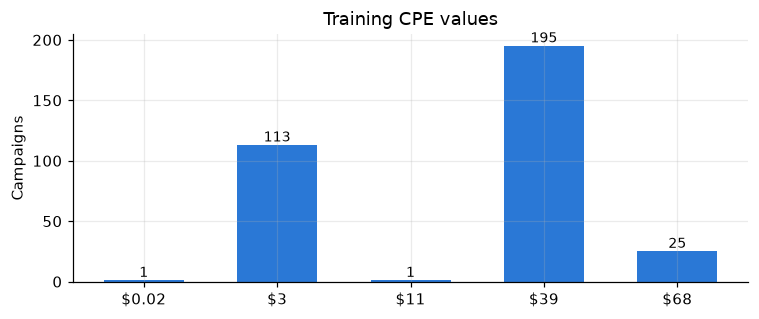

cpe,0.02,3.00,11.00,39.00,68.00
row_0,,,,,
BRAND ALERT,0,0,0,121,0
BRAND PLAY,0,0,0,7,0
BRANDSPOT,0,0,0,0,25
EMAIL ALERT,0,113,0,0,0
INFOSITE,0,0,0,24,0
POINT OF CONTACT,0,0,0,10,0
TARGET LIST MEDIA,1,0,0,24,0
infrequent_sklearn,0,0,1,9,0


In [4]:
sub_cols = [c for c in X_train.columns if c.startswith("sub_product_name_")]
sub_train = X_train[sub_cols].idxmax(axis=1).str.replace("sub_product_name_", "")
sub_val = X_val[sub_cols].idxmax(axis=1).str.replace("sub_product_name_", "")

fig, ax = plt.subplots(figsize=(7, 3))
counts = y_train.value_counts().sort_index()
ax.bar([f"${v:g}" for v in counts.index], counts.values, color=BLUE, width=0.6)
for i, v in enumerate(counts.values):
    ax.text(i, v + 3, str(v), ha="center", fontsize=9)
ax.set_title("Training CPE values"); ax.set_ylabel("Campaigns")
plt.tight_layout(); plt.show()

pd.crosstab(sub_train, y_train)

CPE takes only a few values, and each sub-product maps to one price (Email Alert $3, BrandSpot $68, everything else $39).

## Experiment 0: baselines

In [5]:
rate_card = y_train.groupby(sub_train).median()
score("E0a  baseline: predict mean", np.full(len(y_val), y_train.mean()))
score("E0b  baseline: sub-product rate card", sub_val.map(rate_card).fillna(y_train.median()).values,
      "lookup table, no ML")
pd.DataFrame(results).round(3)

,experiment,MAE,RMSE,R2,within_$1,notes
0,E0a baseline: predict mean,16.991,18.928,-0.029,0.0,
1,E0b baseline: sub-product rate card,0.000,0.000,1.000,1.0,"lookup table, no ML"


## Experiment 1: XGBoost on all features

In [6]:
xgb_all = XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.1, random_state=RANDOM_STATE)
xgb_all.fit(X_train, y_train)
score("E1   XGBoost, all features", xgb_all.predict(X_val), "includes leaky columns")

,experiment,MAE,RMSE,R2,within_$1,notes
0,"E1 XGBoost, all features",0.368,3.109,0.972,0.976,includes leaky columns


In [7]:
# Is budget just CPE x engagements?
implied = X_train["total_budget_spent"] / X_train["total_engagements"]
print(f"budget / engagements == CPE in {np.isclose(implied, y_train, atol=0.01).mean():.0%} of rows")

budget / engagements == CPE in 99% of rows


Budget is built from CPE, so budget-based features leak the answer. Experiment 2 drops them, along with the CPE flags and `product_tier` (CPE bucketed into tiers).

## Experiment 2: remove leaky features

In [8]:
tier_cols = [c for c in X_train.columns if c.startswith("product_tier_")]
leaky = ["total_budget_spent", "log_total_budget_spent", "budget_per_reach", "budget_per_day",
         "spend_near_zero", "budget_anomaly", "cpe_imputed", "cpe_outlier"] + tier_cols

# Also drop the $0.02 label from training: 100x below any real price, almost certainly a typo
keep = y_train != 0.02
Xtr = X_train.drop(columns=leaky)[keep].reset_index(drop=True)
ytr = y_train[keep].reset_index(drop=True)
Xv = X_val.drop(columns=leaky)
print(f"{len(leaky)} leaky columns dropped -> {Xtr.shape[1]} features, {len(ytr)} training rows")

xgb_clean = XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.1, random_state=RANDOM_STATE)
xgb_clean.fit(Xtr, ytr)
score("E2   XGBoost, leakage removed", xgb_clean.predict(Xv))

12 leaky columns dropped -> 149 features, 334 training rows


,experiment,MAE,RMSE,R2,within_$1,notes
0,"E2 XGBoost, leakage removed",0.35,3.093,0.973,0.988,


## Experiment 3: tune with 5-fold CV

In [9]:
xgb_tuned = tune(Xtr, ytr)
pred_tuned = xgb_tuned.predict(Xv)

print(f"train MAE ${mean_absolute_error(ytr, xgb_tuned.predict(Xtr)):.3f} | "
      f"val MAE ${mean_absolute_error(y_val, pred_tuned):.3f}")
score("E3   XGBoost, tuned", pred_tuned)

best params: {'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 300, 'subsample': 1.0} | CV MAE: $0.086
train MAE $0.000 | val MAE $0.349


,experiment,MAE,RMSE,R2,within_$1,notes
0,"E3 XGBoost, tuned",0.349,3.092,0.973,0.988,


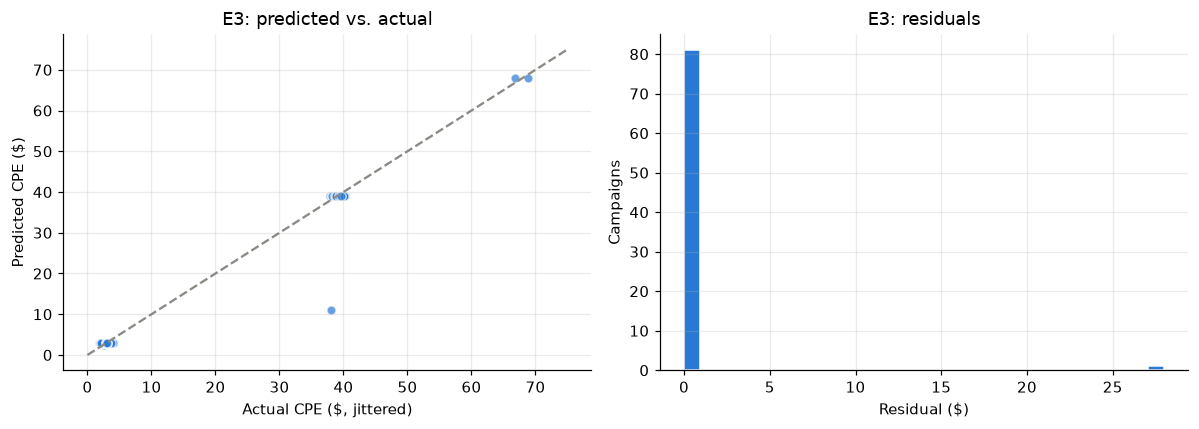

,total_spend,actual_spend_per_engagement,total_engagements,cpe,pred
row,,,,,
val: worst miss,1.0,0.01,184,39.0,11.009003
train: only $11 row,0.0,0.00,595,11.0,NaN


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
jitter = np.random.default_rng(0).uniform(-1.2, 1.2, len(y_val))
axes[0].scatter(y_val + jitter, pred_tuned, s=36, color=BLUE, alpha=0.7, edgecolor="white")
axes[0].plot([0, 75], [0, 75], color=GRAY, ls="--", lw=1.5)
axes[0].set(xlabel="Actual CPE ($, jittered)", ylabel="Predicted CPE ($)", title="E3: predicted vs. actual")
axes[1].hist(y_val - pred_tuned, bins=30, color=BLUE, edgecolor="white")
axes[1].set(xlabel="Residual ($)", ylabel="Campaigns", title="E3: residuals")
plt.tight_layout(); plt.show()

worst = int(np.argmax(np.abs(y_val - pred_tuned)))
cols = ["total_spend", "actual_spend_per_engagement", "total_engagements"]
pd.concat([Xv.loc[[worst], cols].assign(cpe=y_val[worst], pred=pred_tuned[worst], row="val: worst miss"),
           Xtr.loc[ytr == 11, cols].assign(cpe=11.0, pred=np.nan, row="train: only $11 row")]).set_index("row")

The one big miss is a near-zero-spend campaign. The model matched it to the only $11 campaign in training, which also has zero spend. Experiment 4 tests whether dropping that one row fixes it.

## Experiment 4: drop the one-off $11 row

In [11]:
keep11 = ytr != 11
xgb_no11 = tune(Xtr[keep11], ytr[keep11])
score("E4   XGBoost, tuned, no $11 row", xgb_no11.predict(Xv), "chosen after seeing E3 errors")

best params: {'learning_rate': 0.1, 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 300, 'subsample': 1.0} | CV MAE: $0.000


,experiment,MAE,RMSE,R2,within_$1,notes
0,"E4 XGBoost, tuned, no $11 row",0.0,0.0,1.0,1.0,chosen after seeing E3 errors


## Experiment 5: remove product features (what else drives CPE?)

In [12]:
product_feats = [c for c in Xtr.columns if c.startswith(("sub_product_name_", "channel_tag_", "brand_raw_"))
                 or c in ["is_email_alert", "is_brandspot", "is_target_list", "has_channel_tag"]]
Xtr_np, Xv_np = Xtr.drop(columns=product_feats), Xv.drop(columns=product_feats)
print(f"{len(product_feats)} product/channel features dropped -> {Xtr_np.shape[1]} remain")

xgb_np = tune(Xtr_np, ytr)
score("E5   XGBoost, tuned, no product features", xgb_np.predict(Xv_np))

40 product/channel features dropped -> 109 remain


best params: {'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 1, 'n_estimators': 100, 'subsample': 0.8} | CV MAE: $7.849


,experiment,MAE,RMSE,R2,within_$1,notes
0,"E5 XGBoost, tuned, no product features",5.956,10.337,0.693,0.22,


## Experiment 6: treat CPE as a classification problem

In [13]:
# CPE only takes a few values, so predict the price tier as a class
tiers = np.array([3.0, 39.0, 68.0])
keep_t = ytr.isin(tiers)                         # drops the single $11 row (a class can't have 1 example)
to_class = {v: i for i, v in enumerate(tiers)}

clf = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, random_state=RANDOM_STATE)
clf.fit(Xtr[keep_t], ytr[keep_t].map(to_class))
pred_clf = tiers[clf.predict(Xv)]
print(f"tier accuracy: {np.mean(pred_clf == y_val):.1%}")
score("E6   XGBClassifier on price tier", pred_clf)

tier accuracy: 100.0%


,experiment,MAE,RMSE,R2,within_$1,notes
0,E6 XGBClassifier on price tier,0.0,0.0,1.0,1.0,


## Results

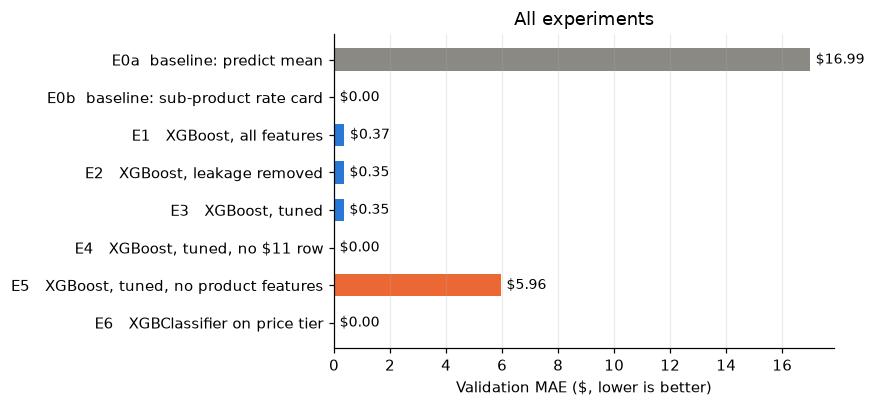

,experiment,MAE,RMSE,R2,within_$1,notes
0,E0a baseline: predict mean,16.991,18.928,-0.029,0.000,
1,E0b baseline: sub-product rate card,0.000,0.000,1.000,1.000,"lookup table, no ML"
2,"E1 XGBoost, all features",0.368,3.109,0.972,0.976,includes leaky columns
3,"E2 XGBoost, leakage removed",0.350,3.093,0.973,0.988,
4,"E3 XGBoost, tuned",0.349,3.092,0.973,0.988,
5,"E4 XGBoost, tuned, no $11 row",0.000,0.000,1.000,1.000,chosen after seeing E3 errors
6,"E5 XGBoost, tuned, no product features",5.956,10.337,0.693,0.220,
7,E6 XGBClassifier on price tier,0.000,0.000,1.000,1.000,


In [14]:
results_df = pd.DataFrame(results).round(3)

fig, ax = plt.subplots(figsize=(8, 3.8))
plot_df = results_df.iloc[::-1]
colors = [GRAY if "baseline" in e else ORANGE if "no product" in e else BLUE for e in plot_df["experiment"]]
ax.barh(plot_df["experiment"], plot_df["MAE"], color=colors, height=0.6)
for i, v in enumerate(plot_df["MAE"]):
    ax.text(v + 0.2, i, f"${v:.2f}", va="center", fontsize=9)
ax.set_xlabel("Validation MAE ($, lower is better)"); ax.set_title("All experiments")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()
results_df

## Feature importance

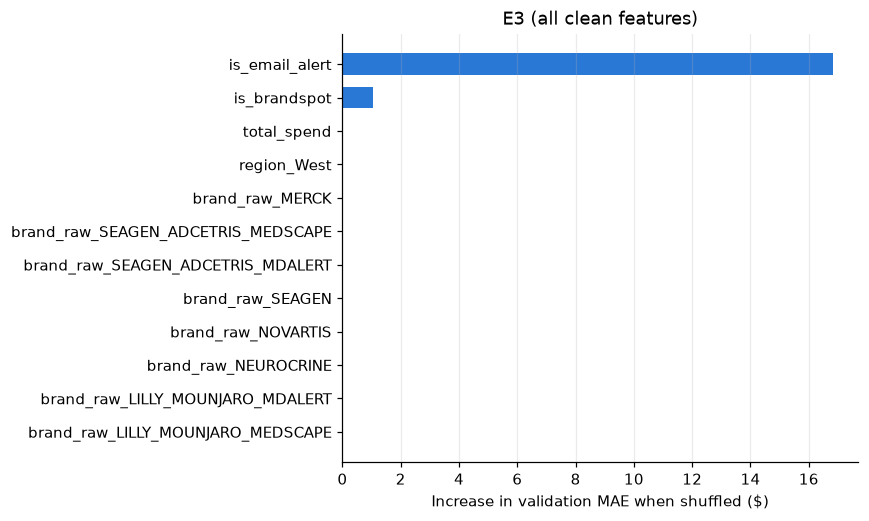

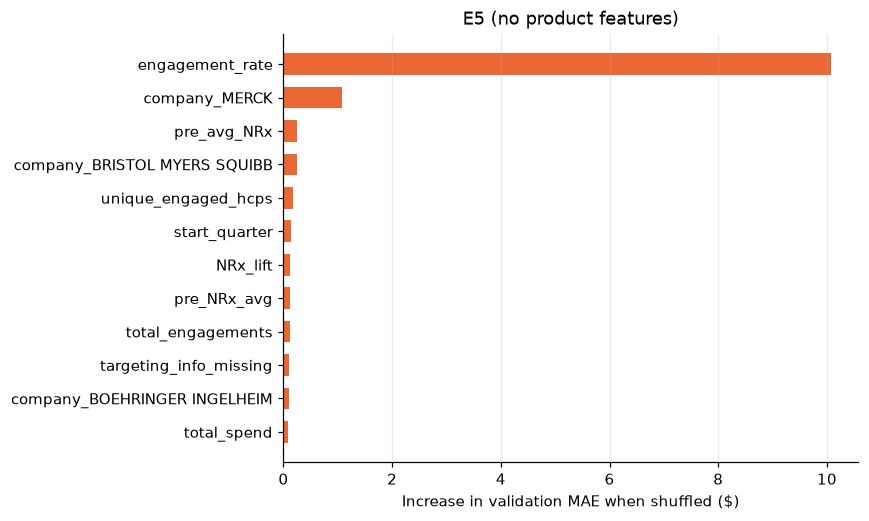

,engagement_rate,company_MERCK,pre_avg_NRx
cpe,,,
3.0,0.398,0.0,43.822
11.0,0.272,0.0,110.959
39.0,0.176,0.0,70.542
68.0,0.247,0.0,93.731


In [15]:
perm = permutation_importance(xgb_tuned, Xv, y_val, n_repeats=30,
                              scoring="neg_mean_absolute_error", random_state=RANDOM_STATE)
plot_importance(pd.Series(perm.importances_mean, index=Xv.columns), "E3 (all clean features)")

perm_np = permutation_importance(xgb_np, Xv_np, y_val, n_repeats=30,
                                 scoring="neg_mean_absolute_error", random_state=RANDOM_STATE)
imp_np = pd.Series(perm_np.importances_mean, index=Xv_np.columns)
plot_importance(imp_np, "E5 (no product features)", color=ORANGE)

# How the top non-product features differ by price
ytr_named = ytr.rename("cpe")
Xtr_np.join(ytr_named).groupby("cpe")[imp_np.nlargest(3).index].median().round(3)

---
# Report

| Experiment | Val MAE | R² | Takeaway |
|---|---|---|---|
| E0a predict mean | $16.99 | −0.03 | floor |
| E0b sub-product rate card | $0.00 | 1.00 | a lookup table is already perfect |
| E1 XGBoost, all features | $0.37 | 0.972 | leaky budget features didn't help: product type already gives the answer |
| E2 leakage removed | $0.35 | 0.973 | same accuracy, now on features that would exist when a campaign is planned |
| E3 tuned (5-fold CV) | $0.35 | 0.973 | tuning barely matters here; train MAE $0.00 shows it fits training perfectly |
| E4 drop the $11 row | $0.00 | 1.00 | the only miss came from one odd training row |
| E5 no product features | $5.96 | 0.69 | without product type, accuracy drops sharply |
| E6 classifier on tier | $0.00 | 1.00 | 100% tier accuracy; classification fits a target with only 3 values |